# SWaT exploratory data analysis and citation audit

This notebook describes the available SWaT data, checks its timestamps and documented attack windows, and reviews the four studies cited in the proposed **SCADA data description**. It fits no anomaly detector and computes no detection recall.

**Two releases must be distinguished:** the literature's December 2015 benchmark spans 11 days and 51 sensor/actuator variables. Our local workbook is **20 July 2019**, with six documented attacks. The default IDS experiment uses only LIT301, AIT301 and AIT302, and only the LIT301 spoofing interval at evaluation. This EDA examines the full workbook and all six intervals.

Primary online sources were checked on **4 October 2026**. Links and evidence locations are included below. Local documentation takes precedence for the local workbook's timestamp and attack annotations.


## 1. Input files and a dependency-light workbook reader

Files come from `scada-data/SWaT-data`. The updated v2 workbook fixes discrete level-switch representations, as explained in `readme.docx`. Its first row groups fields by process stage, the second contains signal names, and the third contains `timestamp`/`value` descriptors; data starts on row 4.

An XLSX is a ZIP of XML files. The small reader below uses Python's standard library so an extra Excel engine is unnecessary. It reads this particular workbook layout, not arbitrary Excel files. Original data and labels are unchanged.


In [1]:
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
from pathlib import Path
from zipfile import ZipFile
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("scada-data/SWaT-data")
WORKBOOK = DATA_DIR / "SWaT_dataset_Jul 19 v2.xlsx"
COMPACT_CSV = DATA_DIR / "swat_july2019_3_sensors.csv"
SENSORS = ["LIT301", "AIT301", "AIT302"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


def read_local_workbook(path):
    namespace = {"s": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    row_tag = "{" + namespace["s"] + "}row"
    records, headers, stage_cells = [], {}, {}
    with ZipFile(path) as archive:
        shared = ["".join(item.itertext()) for item in
                  ET.fromstring(archive.read("xl/sharedStrings.xml")).findall("s:si", namespace)]
        with archive.open("xl/worksheets/sheet1.xml") as sheet:
            for _, row in ET.iterparse(sheet, events=["end"]):
                if row.tag != row_tag:
                    continue
                values = {}
                for cell in row.findall("s:c", namespace):
                    column = cell.get("r").rstrip("0123456789")
                    element = cell.find("s:v", namespace)
                    value = element.text if element is not None else "".join(cell.itertext())
                    values[column] = shared[int(value)] if cell.get("t") == "s" else value
                number = int(row.get("r"))
                if number == 1:
                    stage_cells = values
                elif number == 2:
                    headers = {column: str(value).replace(" ", "") for column, value in values.items()}
                    headers["A"] = "timestamp"
                elif number >= 4 and values.get("A"):
                    records.append({headers[column]: values.get(column, "") for column in headers})
                row.clear()
    inventory, stage = [], None
    for column, name in headers.items():
        stage = stage_cells.get(column) or stage
        if name != "timestamp":
            inventory.append({"signal": name, "stage": stage})
    return pd.DataFrame(records).replace("", np.nan), pd.DataFrame(inventory)


raw, inventory = read_local_workbook(WORKBOOK)
raw["timestamp"] = pd.to_datetime(raw["timestamp"], format="mixed", utc=True)
assert raw.columns.is_unique
for column in inventory.signal:
    converted = pd.to_numeric(raw[column], errors="coerce")
    # Convert fully numeric columns; retain discrete text/status fields as text.
    if converted.notna().sum() == raw[column].notna().sum():
        raw[column] = converted

annotations = pd.read_csv(COMPACT_CSV)
annotations["timestamp"] = pd.to_datetime(annotations.timestamp, format="mixed", utc=True)
data = raw.merge(annotations[["timestamp", "is_attack", "attack_id"]],
                 on="timestamp", how="left", validate="one_to_one")
assert data.is_attack.notna().all(), "Every workbook row must have a schedule annotation."
assert np.array_equal(data.is_attack.to_numpy(), data.attack_id.to_numpy() > 0)
# Confirm that the derived CSV retained the same selected readings.
comparison = raw.merge(annotations[["timestamp", *SENSORS]], on="timestamp", suffixes=("", "_csv"))
for sensor in SENSORS:
    np.testing.assert_allclose(comparison[sensor], comparison[sensor + "_csv"])
print("Workbook:", WORKBOOK)
print("Rows:", len(data), "| workbook signal columns:", len(inventory))
display(data[["timestamp", *SENSORS, "attack_id"]].head())


Workbook: scada-data/SWaT-data/SWaT_dataset_Jul 19 v2.xlsx
Rows: 14996 | workbook signal columns: 77


,timestamp,LIT301,AIT301,AIT302,attack_id
0,2019-07-20 04:30:00+00:00,730.702100,8.522921,256.431274,0
1,2019-07-20 04:30:01+00:00,730.902344,8.522921,256.431274,0
2,2019-07-20 04:30:02.004013+00:00,732.344300,8.522921,256.431274,0
3,2019-07-20 04:30:03.004013+00:00,732.704800,8.522921,256.431274,0
4,2019-07-20 04:30:04+00:00,732.744800,8.522921,256.431274,0


## 2. What is actually present locally?

Count the workbook fields rather than assigning the canonical benchmark's 51-variable count to this later export. Fields include sensors, actuator statuses and process-state variables; a column count is not necessarily a count of distinct physical devices.

The three selected IDS sensors belong to process P3. The broader SWaT plant has six treatment stages; local stage names below come directly from workbook headers. iTrust distinguishes the [2015 and July 2019 releases](https://www.sutd.edu.sg/itrust/itrust-labs/datasets/dataset-characteristics/swat/).


In [2]:
numeric_columns = inventory.signal[inventory.signal.isin(data.select_dtypes(include="number").columns)].tolist()
text_columns = inventory.signal[~inventory.signal.isin(numeric_columns)].tolist()
summary = pd.Series({
    "rows": len(data), "signal columns": len(inventory),
    "numeric signals": len(numeric_columns), "text/status signals": len(text_columns),
    "start UTC": data.timestamp.min(), "end UTC": data.timestamp.max(),
    "elapsed hours": (data.timestamp.max() - data.timestamp.min()).total_seconds() / 3600,
    "calendar dates": data.timestamp.dt.date.nunique(),
    "schedule-normal rows": int((data.attack_id == 0).sum()),
    "all-attack rows": int((data.is_attack == 1).sum()),
    "LIT301 attack rows": int((data.attack_id == 2).sum()),
})
display(summary.to_frame("observed value"))
display(inventory.groupby("stage").size().rename("workbook fields").to_frame())
display(inventory[inventory.signal.isin(SENSORS)])


,observed value
rows,14996
signal columns,77
numeric signals,66
text/status signals,11
start UTC,2019-07-20 04:30:00+00:00
end UTC,2019-07-20 08:39:59.004013+00:00
elapsed hours,4.16639
calendar dates,1
schedule-normal rows,13010
all-attack rows,1986


,workbook fields
stage,
P1,6
P2,18
P3,13
P4,11
P5,18
P6,11


,signal,stage
24,AIT301,P3
25,AIT302,P3
29,LIT301,P3


## 3. Data quality, variability and sampling intervals

Inspect missing values, constants, duplicate timestamps and gaps. A constant actuator can be a legitimate operating state; it is not automatically a defective sensor. Duplicate **readings** are distinct from duplicate timestamped rows.

Expected sampling is approximately one record per second. Fractional timestamps are retained. Time gaps can affect a method whose lags are measured in rows, especially if it silently assumes seconds.


,missing,unique values,dtype,constant,stage
FIT101,0,310,float64,False,P1
LIT101,0,4493,float64,False,P1
MV101,0,3,int64,False,P1
P1_STATE,0,2,int64,False,P1
P101Status,0,2,int64,False,P1
...,...,...,...,...,...
LSL603,0,1,str,True,P6
P6STATE,0,1,int64,True,P6
P601Status,0,2,int64,False,P6
P602Status,0,1,int64,True,P6


Duplicate timestamps: 0
Repeated three-sensor combinations: 6021
Constant signals: ['P102Status', 'LS201', 'LS202', 'LSL203', 'LSLL203', 'P2_STATE', 'P201Status', 'P202Status', 'P204Status', 'P206Status', 'P207Status', 'P208Status', 'P302Status', 'AIT401', 'LS401', 'P4_STATE', 'P402Status', 'P403Status', 'P404Status', 'MV502', 'MV503', 'MV504', 'P5_STATE', 'P501Status', 'P502Status', 'LSH602', 'LSH603', 'LSL601', 'LSL602', 'LSL603', 'P6STATE', 'P602Status', 'P603Status']


,sampling interval (s)
count,14995.000000
mean,1.000267
std,0.044929
min,0.011002
1%,0.995987
50%,1.000000
99%,1.004013
max,5.452011


Intervals > 1.5 s: 6
Non-positive intervals: 0


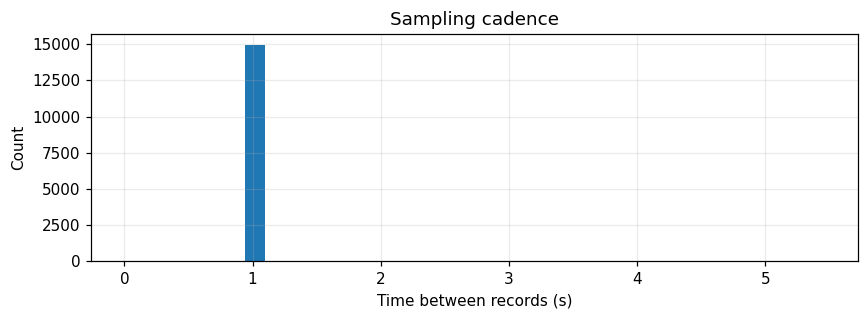

In [3]:
quality = pd.DataFrame({
    "missing": data[inventory.signal].isna().sum(),
    "unique values": data[inventory.signal].nunique(dropna=True),
    "dtype": data[inventory.signal].dtypes.astype(str),
})
quality["constant"] = quality["unique values"] <= 1
quality = quality.join(inventory.set_index("signal"))
display(quality)
print("Duplicate timestamps:", int(data.timestamp.duplicated().sum()))
print("Repeated three-sensor combinations:", int(data[SENSORS].duplicated().sum()))
print("Constant signals:", quality.index[quality.constant].tolist())
interval_seconds = data.timestamp.diff().dt.total_seconds().dropna()
display(interval_seconds.describe(percentiles=[0.01, 0.5, 0.99]).to_frame("sampling interval (s)"))
print("Intervals > 1.5 s:", int((interval_seconds > 1.5).sum()))
print("Non-positive intervals:", int((interval_seconds <= 0).sum()))
fig, axis = plt.subplots(figsize=(8, 3))
axis.hist(interval_seconds, bins=35)
axis.set(xlabel="Time between records (s)", ylabel="Count", title="Sampling cadence")
plt.tight_layout()
plt.show()


## 4. Verify the documented attack schedule and timezone

The workbook's timestamps are UTC; the supplied attack PDF is UTC+8. Convert the six documented intervals explicitly. Each endpoint includes its whole named second, because some samples have fractional seconds. `attack_id = 0` means outside documented attack intervals, not a guarantee of steady-state operation.

The LIT301 spoofing interval has **273 rows**. This matches the paper's reported attack support, but alone does not prove identical preprocessing. All six windows remain visible in this EDA.


In [4]:
schedule = pd.DataFrame([
    (1, "FIT401", "spoof flow", "15:08:46", "15:10:31"),
    (2, "LIT301", "spoof level 835 → 1024", "15:15:00", "15:19:32"),
    (3, "P601", "switch OFF → ON", "15:26:57", "15:30:48"),
    (4, "MV201 + P101", "open valve and turn pump on", "15:38:50", "15:46:20"),
    (5, "MV501", "switch OPEN → CLOSE", "15:54:00", "15:56:00"),
    (6, "P301", "switch ON → OFF", "16:02:56", "16:16:18"),
], columns=["attack_id", "target", "action", "local_start", "local_end"])
for source, target in [("local_start", "start_UTC"), ("local_end", "end_UTC")]:
    schedule[target] = pd.to_datetime("2019-07-20 " + schedule[source]).dt.tz_localize("Asia/Singapore").dt.tz_convert("UTC")
rebuilt_ids = np.zeros(len(data), dtype=int)
whole_second = data.timestamp.dt.floor("s")
for attack in schedule.itertuples():
    mask = whole_second.between(attack.start_UTC, attack.end_UTC)
    assert (rebuilt_ids[mask] == 0).all(), "Attack windows must not overlap."
    rebuilt_ids[mask] = attack.attack_id
np.testing.assert_array_equal(rebuilt_ids, data.attack_id.to_numpy())
schedule["observed rows"] = schedule.attack_id.map(data.attack_id.value_counts()).fillna(0).astype(int)
schedule["inclusive seconds"] = (schedule.end_UTC - schedule.start_UTC).dt.total_seconds().astype(int) + 1
display(schedule)
print("All attack row labels exactly match the UTC-converted schedule.")


,attack_id,target,action,local_start,local_end,start_UTC,end_UTC,observed rows,inclusive seconds
0,1,FIT401,spoof flow,15:08:46,15:10:31,2019-07-20 07:08:46+00:00,2019-07-20 07:10:31+00:00,106,106
1,2,LIT301,spoof level 835 → 1024,15:15:00,15:19:32,2019-07-20 07:15:00+00:00,2019-07-20 07:19:32+00:00,273,273
2,3,P601,switch OFF → ON,15:26:57,15:30:48,2019-07-20 07:26:57+00:00,2019-07-20 07:30:48+00:00,232,232
3,4,MV201 + P101,open valve and turn pump on,15:38:50,15:46:20,2019-07-20 07:38:50+00:00,2019-07-20 07:46:20+00:00,451,451
4,5,MV501,switch OPEN → CLOSE,15:54:00,15:56:00,2019-07-20 07:54:00+00:00,2019-07-20 07:56:00+00:00,121,121
5,6,P301,switch ON → OFF,16:02:56,16:16:18,2019-07-20 08:02:56+00:00,2019-07-20 08:16:18+00:00,803,803


All attack row labels exactly match the UTC-converted schedule.


## 5. Observe all three sensor traces with attack windows

Red shading marks scheduled attacks; IDs identify the schedule above. An attack on another stage may propagate to P3, or may have no visible effect on these three sensors. A plot alone does not establish detectability or causation.


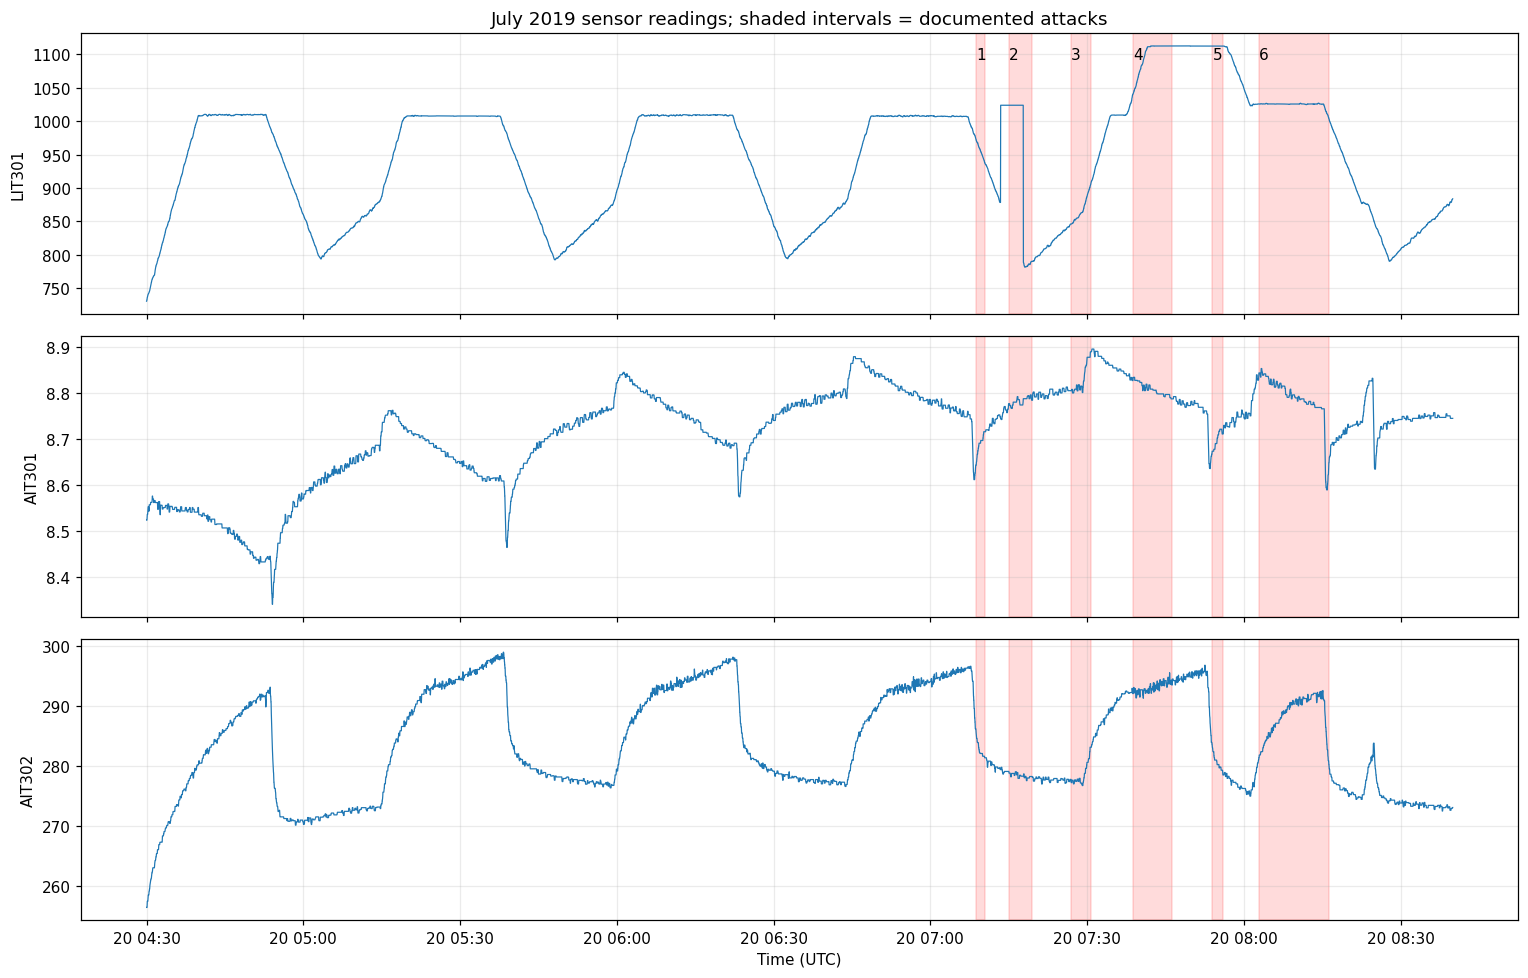

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for axis, sensor in zip(axes, SENSORS):
    axis.plot(data.timestamp, data[sensor], linewidth=0.8)
    for attack in schedule.itertuples():
        axis.axvspan(attack.start_UTC, attack.end_UTC + pd.Timedelta(seconds=1), color="red", alpha=0.14)
        if axis is axes[0]:
            axis.text(attack.start_UTC, 0.95, str(attack.attack_id), va="top", transform=axis.get_xaxis_transform())
    axis.set(ylabel=sensor)
axes[0].set_title("July 2019 sensor readings; shaded intervals = documented attacks")
axes[-1].set_xlabel("Time (UTC)")
plt.tight_layout()
plt.show()


## 6. Focus on LIT301 spoofing and its immediate aftermath

Zoom into attack 2 and compare short before/during/after periods. The preceding five minutes are only a local reference, not the full normal operating distribution. The following five minutes are a recovery reference and must not automatically be treated as clean training data.


LIT301                                                              \
        count        mean     median         std         min          max   
period                                                                      
after     299  809.437204   809.6482   11.224215  790.262146   829.274536   
before    300  947.295475   930.0901   54.223611  878.540800  1024.000000   
during    273  932.262158  1024.0000  116.267000  781.690600  1024.000000   

       AIT301                                                   AIT302  \
        count      mean    median       std       min       max  count   
period                                                                   
after     299  8.797212  8.797586  0.006082  8.784269  8.808407    299   
before    300  8.739911  8.742653  0.018376  8.696459  8.776778    300   
during    273  8.782216  8.783437  0.007986  8.766375  8.795921    273   

                                                                  
              mean      median       std         min         max  
period                                                            
after   277.812484  277.892300  0.288518  277.021576  278.225250  
before  280.056936  279.864258  0.861936  278.660600  281.656952  
during  278.408634  278.327667  0.355043  277.585000  279.121582

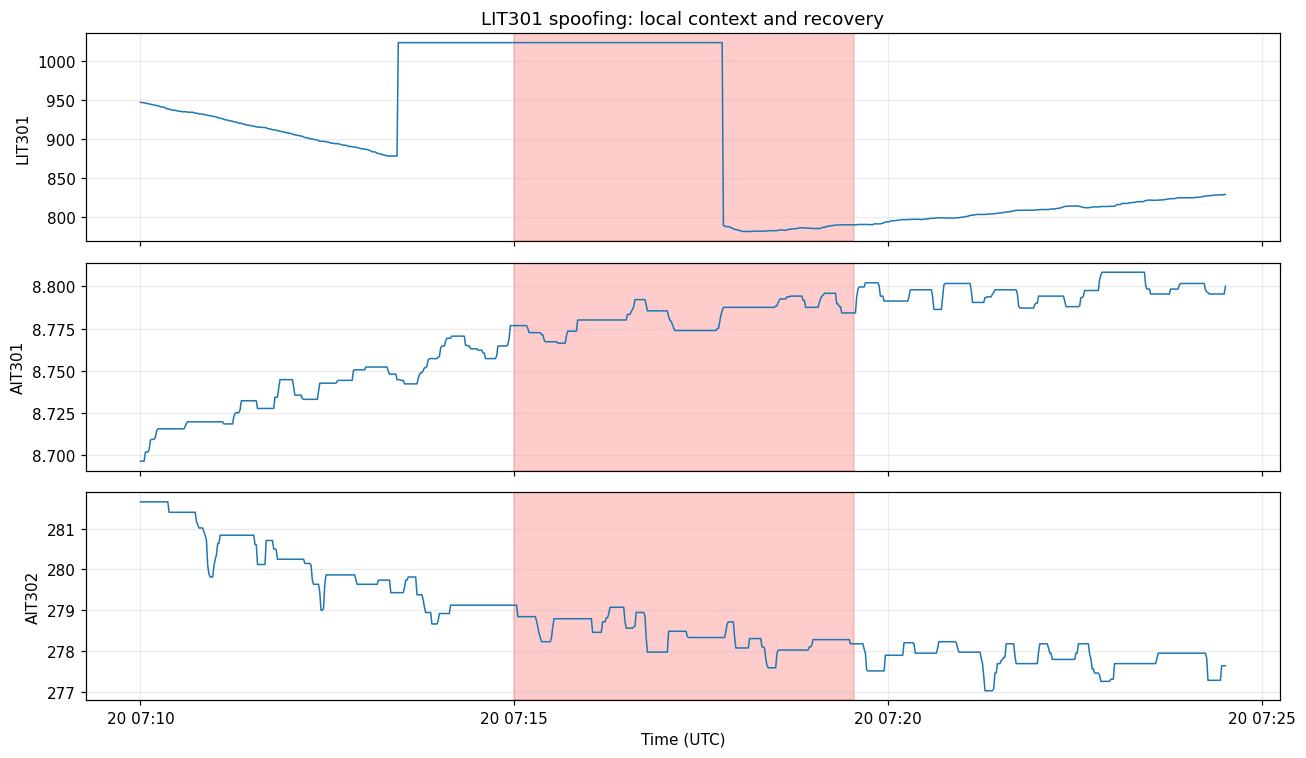

In [6]:
attack2 = schedule.loc[schedule.attack_id == 2].iloc[0]
zoom = data[data.timestamp.between(attack2.start_UTC - pd.Timedelta(minutes=5),
                                   attack2.end_UTC + pd.Timedelta(minutes=5))].copy()
zoom["period"] = np.select(
    [zoom.timestamp < attack2.start_UTC, zoom.timestamp.dt.floor("s") <= attack2.end_UTC],
    ["before", "during"], default="after",
)
display(zoom.groupby("period")[SENSORS].agg(["count", "mean", "median", "std", "min", "max"]))
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for axis, sensor in zip(axes, SENSORS):
    axis.plot(zoom.timestamp, zoom[sensor], linewidth=1)
    axis.axvspan(attack2.start_UTC, attack2.end_UTC + pd.Timedelta(seconds=1), color="red", alpha=0.2)
    axis.set_ylabel(sensor)
axes[0].set_title("LIT301 spoofing: local context and recovery")
axes[-1].set_xlabel("Time (UTC)")
plt.tight_layout()
plt.show()


## 7. Distribution differences and temporal behaviour

Compare schedule-normal rows with LIT301 attack rows and other attacks separately. Density-normalized histograms compare **shape**, not prevalence. All attack windows are excluded from the normal group. Inspect one-step changes and short-window variability as well as levels: a plausible but frozen value can differ mainly in its dynamics.

These are retrospective descriptions using known labels. They are not a feature-selection procedure for an untouched detector test set.


LIT301                                                  \
                 count       median         mean         std       min   
group                                                                    
LIT301 spoofing    273  1024.000000   932.262158  116.267000  781.6906   
other attacks     1713  1025.898800  1025.234089   76.154598  846.1372   
schedule normal  13010   958.227882   936.589944   88.472211  730.7021   

                            AIT301                                          \
                        max  count    median      mean       std       min   
group                                                                        
LIT301 spoofing  1024.00000    273  8.783437  8.782216  0.007986  8.766375   
other attacks    1112.77563   1713  8.798002  8.786976  0.053897  8.588675   
schedule normal  1112.77563  13010  8.736827  8.707742  0.103983  8.339394   

                          AIT302                                    \
                      max  count      median        mean       std   
group                                                                
LIT301 spoofing  8.795921    273  278.327667  278.408634  0.355043   
other attacks    8.889974   1713  290.082581  287.545991  5.490847   
schedule normal  8.895800  13010  280.504517  283.299152  8.806450   

                                         
                        min         max  
group                                    
LIT301 spoofing  277.585000  279.121582  
other attacks    276.765472  295.588700  
schedule normal  256.431274  299.020416

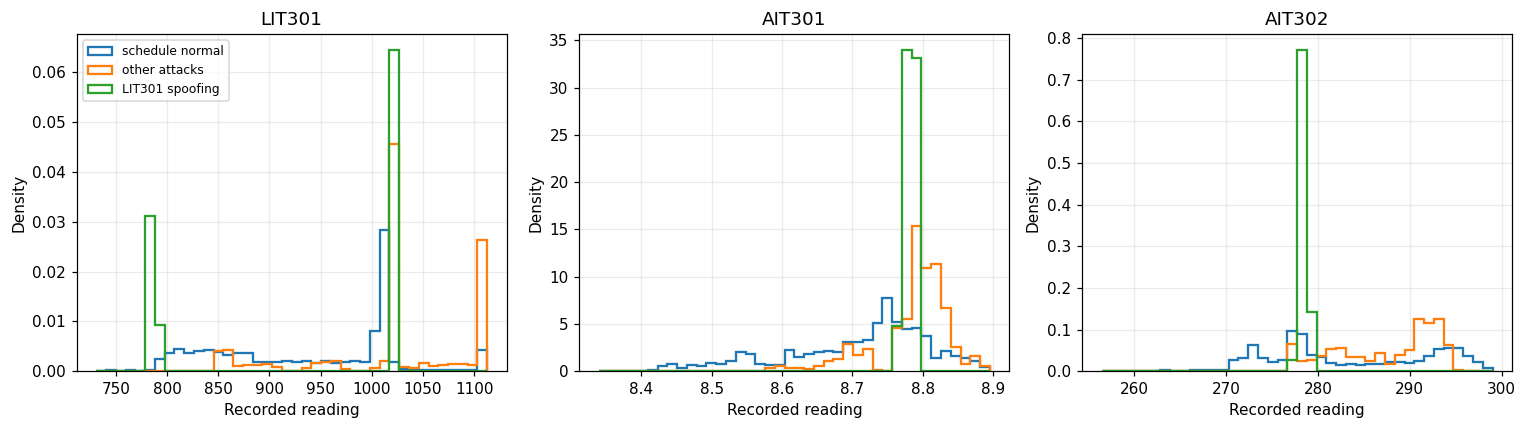

,LIT301 abs change,LIT301 rolling std,AIT301 abs change,AIT301 rolling std,AIT302 abs change,AIT302 rolling std
group,,,,,,
LIT301 spoofing,0.0,0.000028,0.0,0.000771,0.0,0.078654
other attacks,0.0,0.096706,0.0,0.001075,0.0,0.223005
schedule normal,0.0,0.447240,0.0,0.001053,0.0,0.137683


In [7]:
data["group"] = np.select([data.attack_id == 0, data.attack_id == 2],
                          ["schedule normal", "LIT301 spoofing"], default="other attacks")
display(data.groupby("group")[SENSORS].agg(["count", "median", "mean", "std", "min", "max"]))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, sensor in zip(axes, SENSORS):
    edges = np.histogram_bin_edges(data[sensor].dropna(), bins=40)
    for name, group in data.groupby("group", sort=False):
        axis.hist(group[sensor].dropna(), bins=edges, density=True, histtype="step", linewidth=1.5, label=name)
    axis.set(title=sensor, xlabel="Recorded reading", ylabel="Density")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

dynamics = pd.DataFrame({"group": data.group})
for sensor in SENSORS:
    dynamics[sensor + " abs change"] = data[sensor].diff().abs()
    dynamics[sensor + " rolling std"] = data[sensor].rolling(10, min_periods=10).std()
display(dynamics.groupby("group").median())
# Changes at window boundaries intentionally remain visible in this retrospective EDA.


## 8. Relationships between signals and serial dependence

Correlation is association, not proof of a physical causal link. Compare the three selected sensors by operating group. Autocorrelation describes persistence and explains why randomly split neighbouring rows can yield optimistic generalization.

The local three-sensor view omits the actuator commands and most process measurements. An invisible attack cannot be assumed detectable from it.


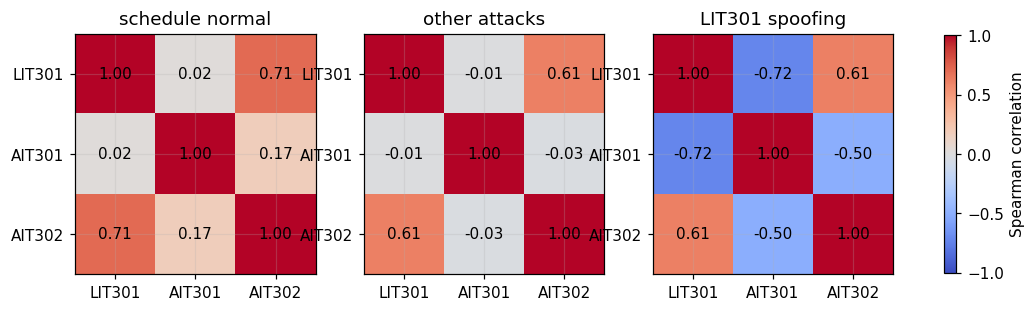

,LIT301,AIT301,AIT302
lag (records),,,
1,0.999693,0.999866,0.999852
5,0.998392,0.998486,0.998766
10,0.996592,0.995690,0.997448
30,0.987810,0.983152,0.988562
60,0.970406,0.967181,0.964805


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for axis, (name, group) in zip(axes, data.groupby("group", sort=False)):
    correlation = group[SENSORS].corr(method="spearman")
    image = axis.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
    axis.set(xticks=range(3), xticklabels=SENSORS, yticks=range(3), yticklabels=SENSORS, title=name)
    for i in range(3):
        for j in range(3):
            value = correlation.iloc[i, j]
            axis.text(j, i, f"{value:.2f}", ha="center", va="center")
fig.colorbar(image, ax=axes.tolist(), shrink=0.7, label="Spearman correlation")
plt.show()

autocorrelation = pd.DataFrame({
    sensor: [data[sensor].autocorr(lag=lag) for lag in (1, 5, 10, 30, 60)]
    for sensor in SENSORS
}, index=pd.Index([1, 5, 10, 30, 60], name="lag (records)"))
display(autocorrelation)


## 9. Identify safe normal candidates and compare experiment scopes

The IDS notebook excludes normal-labelled rows whose previous 30 records contain any of the six attacks. It also excludes the initial incomplete history. This EDA counts those exclusions. A 30-record guard does not establish that all recovery effects have ended.

The article's wording about training on seven normal days applies to the **2015 benchmark**, not the mixed July 2019 recording. For our compact experiment the fitting pool is selected from guarded normal intervals in this one recording. No detector is fitted here.


In [9]:
recent_attack = data.is_attack.rolling(31, min_periods=1).max().to_numpy() > 0
has_history = np.arange(len(data)) >= 30
safe_normal = (data.is_attack.to_numpy() == 0) & ~recent_attack & has_history
print("Schedule-normal rows:", int((data.attack_id == 0).sum()))
print("Guarded normal candidates:", int(safe_normal.sum()))
print("Excluded schedule-normal rows:", int(((data.attack_id == 0) & ~safe_normal).sum()))
display(pd.DataFrame({
    "scope": ["all six July 2019 attacks", "LIT301-only IDS evaluation"],
    "attack scenarios": [6, 1],
    "attack rows": [int(data.is_attack.sum()), int((data.attack_id == 2).sum())],
    "available guarded normal pool": [int(safe_normal.sum())] * 2,
}))
# The IDS notebook subsequently splits this pool; it does not test on all of it.


Schedule-normal rows: 13010
Guarded normal candidates: 12800
Excluded schedule-normal rows: 210


,scope,attack scenarios,attack rows,available guarded normal pool
0,all six July 2019 attacks,6,1986,12800
1,LIT301-only IDS evaluation,1,273,12800


### Observed findings from this local recording

The workbook contains **14,996 rows and 77 recorded fields**, including statuses and process states. There are **no duplicate timestamps**, although six sampling intervals exceed 1.5 seconds. The three-sensor combinations repeat in 6,021 rows; repeated values alone do not indicate an attack.

There are **1,986 schedule-labelled attack rows** across six windows; **273** belong to LIT301 spoofing. Of 13,010 rows outside attack windows, **12,800** survive the 30-record history guard. These are candidate normal rows, not independently certified clean operating states.

During attack 2, all three sensors lie inside their respective **pooled outside-window minimum–maximum ranges**. For LIT301, the attack interval ranges from approximately 781.69 to 1024.00, while the pooled outside-window range is approximately 730.70 to 1112.78. A simple full-range check therefore cannot isolate this event. This is a retrospective observation: outside-window data includes recovery periods, and a clean pre-attack reference may have a different range. Temporal patterns and conditional relationships deserve examination without claiming detection performance.

Lag-1 autocorrelation exceeds **0.999** for each selected sensor in the full recording. Randomly distributing neighbouring records across training and testing can therefore make independence assumptions unrealistic. A future chronological evaluation should distinguish normal transitions, attacks and recovery periods.


## 10. Audit the dataset description before using it in the paper

| Claim in the supplied text | Assessment and suggested qualification |
|---|---|
| Six-stage plant and 51 sensor/actuator variables | Canonical benchmark context; do not assign its field count to the local 2019 workbook. |
| 11 days: seven normal and four attack days | Correct for December 2015; incorrect as a description of our local one-day July 2019 input. |
| Exactly 36 attacks in the public release | Several papers evaluate 36 scenarios, but iTrust's official 2015 description lists **41 launched attacks**. Distinguish the evaluated subset from launched scenarios. |
| Local evaluation uses 36 attacks | Our default experiment evaluates one July 2019 attack, 273 observations. The local schedule has six attacks. |
| Normal-only learning is a zero-day benchmark | It tests generalization without attack-class fitting; it does not demonstrate coverage of all real-world zero-day mechanisms. |

The release distinction and launched-scenario count follow [iTrust's dataset catalogue](https://www.sutd.edu.sg/itrust/itrust-labs/datasets/dataset-characteristics/swat/). The six local windows and timezones follow the supplied PDF/readme, whose labels were independently checked above.


## 11. Check the four cited studies against primary papers

**Boateng, Bruce and Talbert (2022)** — DOI [10.1109/ACCESS.2022.3218624](https://doi.org/10.1109/ACCESS.2022.3218624). The [author-posted paper](https://www.researchgate.net/publication/365101105_Anomaly_Detection_for_a_Water_Treatment_System_Based_on_One-class_Neural_Network), Section V and Conclusion, supports superior scenario recall in **15 of 36** comparisons. This is not “only 15 attacks detected.” Section V reports aggregate precision 94%, recall 82%, F1 87%, and a separately configured recall-focused variant. The text's scenario-comparison wording is reasonable; specify the comparison set/configuration.

**Fährmann et al. (2022)** — DOI [10.3390/s22082886](https://doi.org/10.3390/s22082886). [Institutional full text](https://publica-rest.fraunhofer.de/server/api/core/bitstreams/2adefe32-ae68-437a-9a46-2aa0dcabdea9/content), Table 7: **LW-LSTM-VAE-M, P99%** has precision 73.91%, recall **82.16%**, F1 77.82%. The STD variant has precision 89.88%, recall 79.65%, F1 84.46%. State model and threshold; “~82% detection rate” is recall, not attack-scenario coverage. Sections 3.6/4.2 describe normal-training thresholds and an 80/20 normal split, but also inherited K–S feature screening. Do not assert a fully label-free selection protocol without checking its provenance. Their architecture uses 36 selected SWaT features, not all 51.

**Koutroulis, Mutlu and Kern (2023)** — DOI [10.3390/s23010257](https://doi.org/10.3390/s23010257). [Full text](https://pmc.ncbi.nlm.nih.gov/articles/PMC9823548/), Table 5: precision 1.0, recall 0.889, F1 **0.941**, 32 detected scenarios. “Highest F1 and zero false alarms” is supported within their comparison. Section 4.3 uses point-adjusted/event-based matching, so this is not directly comparable to our pointwise IDS metrics. Causal relations use domain knowledge and component forecasting; describing the method as unrestricted causal discovery would overstate it.

**Sun et al. (2024 journal version; 2023 preprint)** — DOI [10.1016/j.cose.2023.103570](https://doi.org/10.1016/j.cose.2023.103570). The [author preprint](https://arxiv.org/pdf/2311.02378), Table 6, confirms precision **99.0%**, accuracy **94.84%**, recall **66.93%**, F1 **79.87%**. Section 6.4 uses 30-record windows with stride 10; Section 6.2 reduces SWaT to five principal components. These details differ from a three-sensor pointwise test. The exact numbers were checked in the preprint; an independent full-text check of the journal version was not available.


## 12. Corrections to the cross-study conclusions

The four figures are not a common leaderboard: scenario-wise comparisons, window recall, event-adjusted F1 and a thresholded pointwise test measure different things. The verified studies support normal-behaviour learning, but that does not itself certify that every preprocessing, model-selection or reporting decision avoided attack outcomes.

In particular, **“precision is consistently high” is too strong**: Fährmann's cited 82.16%-recall configuration has 73.91% precision. Its different threshold improves precision while changing recall. Nor do these four studies establish the universal claim that no method anywhere in the literature catches every attack type. Write that detection is incomplete in these reported settings and depends on what is observable.

Correction to an initial audit impression: Fährmann Section 4.2 explicitly excludes anomalous test data from model training. The direct paper does not establish a blanket allegation of attack-label fitting. [Koutroulis's related-work discussion](https://pmc.ncbi.nlm.nih.gov/articles/PMC9823548/) characterizes the earlier K–S screening as supervised; report that as their characterization, while distinguishing it from verified network-training protocol. Avoid both unsupported allegations and unsupported guarantees.

Do not combine one variant's precision with another variant's recall, convert “best recall in 15 scenarios” into “15 scenarios detected,” or compare the July 2019 single-attack test directly with 2015 all-stage scores.


## 13. Suggested replacement for the local-data paragraph

For the present SCADA experiment we use the July 2019 SWaT historian recording and its supplied attack schedule. The local workbook contains a single recording on 20 July 2019 and six documented attacks. We retain LIT301, AIT301 and AIT302 for the compact detector. Workbook timestamps are UTC, whereas scheduled attack times are UTC+8; annotations are converted before assigning attack windows. The default evaluation isolates the LIT301 spoofing interval, which contains 273 observations, and excludes the other documented attacks from fitting and evaluation. Fitting and calibration data are drawn from normal-labelled intervals with a 30-record post-attack history guard. This setup differs from the December 2015, 11-day benchmark used in the cited studies; published scores therefore provide methodological context rather than directly comparable performance targets.

Keep the broader testbed description separately, explicitly naming the 2015 release and distinguishing its launched attacks from each paper's evaluated subset. Literature claims should retain their method variant, threshold and evaluation unit.


## 14. What this EDA can and cannot establish

The executed tables and plots establish the local data's coverage, quality, schedule annotations, sensor distributions and temporal relationships. They do not establish which attacks an IDS catches, detector precision/recall, or energy and latency performance. Those require a separately frozen evaluation.

The IDS notebook remains unexecuted. This EDA is descriptive and uses known labels retrospectively; its plots should not guide new test-set tuning while preserving a claim of untouched evaluation.
